# 03 · Grandes volúmenes de datos con poca RAM

Tarde o temprano un conjunto de datos no cabrá cómodamente en memoria: un portátil tiene de 8 a 16 GB, un
servidor pequeño en la nube de 2 a 4 GB, y pandas suele necesitar varias veces el tamaño del archivo mientras
carga. Este módulo muestra cómo medir la memoria con honestidad y las técnicas, y las bibliotecas
alternativas, que la mantienen bajo control.

**Aprenderás**
1. Cómo medir la memoria: el tamaño de los objetos y el **pico** de memoria de un proceso completo
2. Reducir un DataFrame: tipos numéricos más pequeños y categorías
3. Procesamiento por flujo: trabajar por bloques o con generadores en lugar de cargarlo todo
4. Archivos columnares: leer solo las columnas y filas necesarias
5. Alternativas a pandas: **Polars**, **DuckDB**, **PyArrow** (y cuándo tienen sentido Dask o Spark)
6. Una comparativa: la misma consulta de seis maneras, con tiempos y pico de memoria medidos
7. **PySpark** para datos que no caben en una máquina: las mismas consultas con la API de DataFrame y con SQL

## 1. Medir la memoria
`sys.getsizeof` da el tamaño de un objeto de Python (no de lo que contiene); `DataFrame.memory_usage(deep=True)`
da el tamaño real de una tabla, cadenas incluidas; `psutil` informa de lo que usa el proceso entero.

In [1]:
import sys, os, psutil
import numpy as np
import pandas as pd

proc = psutil.Process(os.getpid())
print(f"este kernel usa ahora {proc.memory_info().rss / 1e6:.0f} MB")

print(sys.getsizeof(1), "bytes for an int,", sys.getsizeof(1.0), "for a float,", sys.getsizeof("a"), "for a 1-character str")
print(f"a NumPy array of 1M float64: {np.zeros(1_000_000).nbytes / 1e6:.0f} MB; a list of 1M floats: "
      f"~{(sys.getsizeof([0.0] * 1_000_000) + 1_000_000 * sys.getsizeof(0.0)) / 1e6:.0f} MB")

este kernel usa ahora 132 MB
28 bytes for an int, 24 for a float, 42 for a 1-character str
a NumPy array of 1M float64: 8 MB; a list of 1M floats: ~32 MB


## 2. Reducir un DataFrame
pandas usa por defecto números de 64 bits y cadenas de Python. La mayoría de las columnas necesitan mucho menos.

In [2]:
rng = np.random.default_rng(0)
n = 1_000_000
df = pd.DataFrame({
    "sensor_id": rng.integers(1, 500, n),                    # fits in int16
    "temperature": rng.normal(21, 4, n),                     # float32 is plenty for a sensor
    "humidity": rng.integers(0, 101, n),                     # fits in uint8
    "status": rng.choice(["ok", "warning", "fault"], n, p=[0.9, 0.08, 0.02]),  # 3 distinct values
    "site": rng.choice([f"site_{i}" for i in range(40)], n),
})

def mb(frame):
    return frame.memory_usage(deep=True).sum() / 1e6

before = mb(df)
small = df.assign(
    sensor_id=pd.to_numeric(df["sensor_id"], downcast="integer"),
    temperature=df["temperature"].astype("float32"),
    humidity=pd.to_numeric(df["humidity"], downcast="unsigned"),
    status=df["status"].astype("category"),
    site=df["site"].astype("category"),
)
print(df.dtypes.to_dict()); print(small.dtypes.to_dict())
print(f"antes {before:.0f} MB -> después {mb(small):.0f} MB ({before / mb(small):.1f} veces menos)")

{'sensor_id': dtype('int64'), 'temperature': dtype('float64'), 'humidity': dtype('int64'), 'status': dtype('O'), 'site': dtype('O')}
{'sensor_id': dtype('int16'), 'temperature': dtype('float32'), 'humidity': dtype('uint8'), 'status': CategoricalDtype(categories=['fault', 'ok', 'warning'], ordered=False, categories_dtype=object), 'site': CategoricalDtype(categories=['site_0', 'site_1', 'site_10', 'site_11', 'site_12',
                  'site_13', 'site_14', 'site_15', 'site_16', 'site_17',
                  'site_18', 'site_19', 'site_2', 'site_20', 'site_21',
                  'site_22', 'site_23', 'site_24', 'site_25', 'site_26',
                  'site_27', 'site_28', 'site_29', 'site_3', 'site_30',
                  'site_31', 'site_32', 'site_33', 'site_34', 'site_35',
                  'site_36', 'site_37', 'site_38', 'site_39', 'site_4',
                  'site_5', 'site_6', 'site_7', 'site_8', 'site_9'],
, ordered=False, categories_dtype=object)}
antes 131 MB -> después 9 MB (14

Una **categoría** guarda cada cadena distinta una sola vez y almacena por fila un código entero pequeño. Es la
mayor mejora individual para columnas de texto con pocos valores distintos, y agrupar por ella también es
más rápido:

In [3]:
import timeit
t_obj = timeit.timeit(lambda: df.groupby("site")["temperature"].mean(), number=5) / 5
t_cat = timeit.timeit(lambda: small.groupby("site", observed=True)["temperature"].mean(), number=5) / 5
print(f"groupby sobre texto: {t_obj * 1000:.0f} ms, sobre categoría: {t_cat * 1000:.0f} ms")

groupby sobre texto: 88 ms, sobre categoría: 29 ms


## 3. Procesamiento por flujo: bloques y generadores
Si el resultado es pequeño (una suma, un recuento, una media), no hace falta tener todas las filas a la vez.

In [4]:
import tempfile
tmp = tempfile.mkdtemp()

# a 3-million-row dataset, written once as CSV and as Parquet, used for the rest of the module
N = 3_000_000
big = pd.DataFrame({
    "sensor_id": rng.integers(1, 500, N).astype("int16"),
    "temperature": rng.normal(21, 4, N).astype("float32"),
    "status": pd.Categorical(rng.choice(["ok", "warning", "fault"], N, p=[0.9, 0.08, 0.02])),
    "site": pd.Categorical(rng.choice([f"site_{i}" for i in range(40)], N)),
    "note": rng.choice(["", "manual check", "recalibrated", "battery low"], N),
})
CSV, PARQUET = os.path.join(tmp, "big.csv"), os.path.join(tmp, "big.parquet")
big.to_csv(CSV, index=False)
big.to_parquet(PARQUET, index=False, row_group_size=250_000)
print(f"CSV {os.path.getsize(CSV) / 1e6:.0f} MB, Parquet {os.path.getsize(PARQUET) / 1e6:.0f} MB")
del big

CSV 104 MB, Parquet 25 MB


In [5]:
# temperatura media de las lecturas 'fault' por sitio, leyendo el CSV de 250.000 en 250.000 filas
sums, counts = {}, {}
for chunk in pd.read_csv(CSV, chunksize=250_000, usecols=["site", "status", "temperature"]):
    faults = chunk[chunk["status"] == "fault"]
    g = faults.groupby("site")["temperature"]
    for site, s in g.sum().items():
        sums[site] = sums.get(site, 0.0) + s
    for site, c in g.count().items():
        counts[site] = counts.get(site, 0) + c
streamed = pd.Series({k: sums[k] / counts[k] for k in sums}).sort_index()
print(streamed.head())

site_0     21.057986
site_1     21.014257
site_10    20.881563
site_11    20.891889
site_12    21.071960
dtype: float64


In [6]:
# la misma idea con un generador simple: un flujo que nunca tiene el archivo entero en memoria
def read_lines(path):
    with open(path) as f:
        next(f)                                   # skip the header
        for line in f:
            yield line.rstrip("\n").split(",")

def faults_only(rows):
    return (r for r in rows if r[2] == "fault")   # columns: sensor_id, temperature, status, site, note

count = sum(1 for _ in faults_only(read_lines(CSV)))
print(f"filas fault: {count:,}")

filas fault: 59,835


## 4. Archivos columnares: leer solo lo necesario
Parquet guarda cada columna por separado y conserva estadísticas de mínimo y máximo por bloque de filas (un
*row group*). Por eso un lector puede saltarse las columnas que no necesita (**poda de columnas**) y bloques
enteros de filas que no pueden cumplir un filtro (**predicate pushdown**, empuje de predicados).

In [7]:
import pyarrow.parquet as pq
meta = pq.ParquetFile(PARQUET).metadata
print(f"{meta.num_rows:,} rows in {meta.num_row_groups} row groups, {meta.num_columns} columns")

subset = pd.read_parquet(PARQUET, columns=["site", "temperature"], filters=[("status", "==", "fault")])
print(subset.shape, f"{mb(subset):.1f} MB cargados en lugar de la tabla entera")

3,000,000 rows in 12 row groups, 5 columns
(59835, 2) 0.3 MB cargados en lugar de la tabla entera


## 5. Alternativas a pandas

| Biblioteca | Qué es | Puntos fuertes |
|---|---|---|
| **Polars** | biblioteca de DataFrames escrita en Rust, construida sobre Apache Arrow | multihilo, consultas diferidas con optimizador, procesamiento por flujo para datos mayores que la RAM |
| **DuckDB** | una base de datos SQL analítica que se ejecuta dentro del proceso | SQL directamente sobre archivos Parquet/CSV, ejecución fuera de memoria, consumo de memoria muy bajo |
| **PyArrow** | la biblioteca de Python para Apache Arrow, el formato columnar en memoria que comparten las demás | intercambio sin copias entre herramientas, datasets, funciones de cálculo |
| **Dask** | API parecida a pandas, repartida en particiones | escala código pandas a muchos núcleos o a un clúster |
| **Spark (PySpark)** | motor distribuido | datos que necesitan un clúster (cientos de GB y más) |

Regla práctica: hasta unos pocos GB, pandas con buenos tipos basta; por encima, o con poca memoria, Polars o
DuckDB sobre Parquet suelen resolverlo en una sola máquina; recurre a Dask o Spark solo cuando una máquina de
verdad no alcance.

In [8]:
import polars as pl, duckdb

print(pl.scan_parquet(PARQUET)                 # lazy: nothing is read yet
        .filter(pl.col("status") == "fault")
        .group_by("site").agg(pl.col("temperature").mean())
        .sort("site").head(3).collect())

print(duckdb.sql(f"select site, avg(temperature) as t from '{PARQUET}' where status = 'fault' "
                 "group by site order by site limit 3").df())

shape: (3, 2)
┌─────────┬─────────────┐
│ site    ┆ temperature │
│ ---     ┆ ---         │
│ cat     ┆ f32         │
╞═════════╪═════════════╡
│ site_0  ┆ 21.057985   │
│ site_1  ┆ 21.014257   │
│ site_10 ┆ 20.881563   │
└─────────┴─────────────┘
      site          t
0   site_0  21.057986
1   site_1  21.014257
2  site_10  20.881563


## 6. Comparativa: una consulta, seis maneras
Cada enfoque se ejecuta en un **proceso de Python nuevo** para medir su pico de memoria (el máximo de memoria
residente según el sistema operativo) por separado, sin nada de lo que ya tiene este notebook. Las bibliotecas
nativas reservan memoria fuera de Python, así que es la única forma justa de compararlas.

In [9]:
import subprocess, json, textwrap

QUERY = "mean temperature of fault readings per site"
approaches = {
    "pandas read_csv (all columns)": f"""
df = pd.read_csv({CSV!r})
r = df[df.status == 'fault'].groupby('site').temperature.mean()""",
    "pandas read_csv (3 columns, typed)": f"""
df = pd.read_csv({CSV!r}, usecols=['site', 'status', 'temperature'], dtype={{'site': 'category', 'status': 'category', 'temperature': 'float32'}})
r = df[df.status == 'fault'].groupby('site', observed=True).temperature.mean()""",
    "pandas read_csv in chunks": f"""
parts = [c[c.status == 'fault'] for c in pd.read_csv({CSV!r}, usecols=['site', 'status', 'temperature'], chunksize=250_000)]
r = pd.concat(parts).groupby('site').temperature.mean()""",
    "pandas read_parquet (pruned + filtered)": f"""
df = pd.read_parquet({PARQUET!r}, columns=['site', 'temperature'], filters=[('status', '==', 'fault')])
r = df.groupby('site', observed=True).temperature.mean()""",
    "Polars lazy scan": f"""
import polars as pl
r = pl.scan_parquet({PARQUET!r}).filter(pl.col('status') == 'fault').group_by('site').agg(pl.col('temperature').mean()).collect()""",
    "DuckDB SQL": f"""
import duckdb
r = duckdb.sql("select site, avg(temperature) from '{PARQUET}' where status = 'fault' group by site").df()""",
}

def run(snippet):
    # Peak memory = VmHWM ("high water mark") from /proc/self/status, in kB. Unlike getrusage's
    # ru_maxrss it belongs to the new program only: Linux carries ru_maxrss over from the parent
    # (this notebook) through fork and exec, which would hide every difference. (Linux only.)
    prog = ("import time, pandas as pd\nt0 = time.perf_counter()\n" + textwrap.dedent(snippet) +
            "\nhwm = next(l for l in open('/proc/self/status') if l.startswith('VmHWM')).split()[1]"
            "\nprint(time.perf_counter() - t0, hwm)")
    out = subprocess.run([sys.executable, "-c", prog], capture_output=True, text=True, check=True).stdout.split()
    return float(out[-2]), int(out[-1]) / 1024          # seconds, MB

baseline_mb = run("pass")[1]                            # what an empty python + pandas import costs
bench = pd.DataFrame([dict(approach=k, seconds=s, peak_mb=m - baseline_mb) for k, (s, m) in
                      ((k, run(v)) for k, v in approaches.items())]).set_index("approach").round(2)
print(f"{QUERY}; peak memory above a bare 'import pandas' process ({baseline_mb:.0f} MB)")
bench

mean temperature of fault readings per site; peak memory above a bare 'import pandas' process (99 MB)


,seconds,peak_mb
approach,,
pandas read_csv (all columns),2.85,229.20
"pandas read_csv (3 columns, typed)",1.63,37.60
pandas read_csv in chunks,2.40,42.86
pandas read_parquet (pruned + filtered),0.14,126.16
Polars lazy scan,0.45,95.05
DuckDB SQL,0.15,66.78


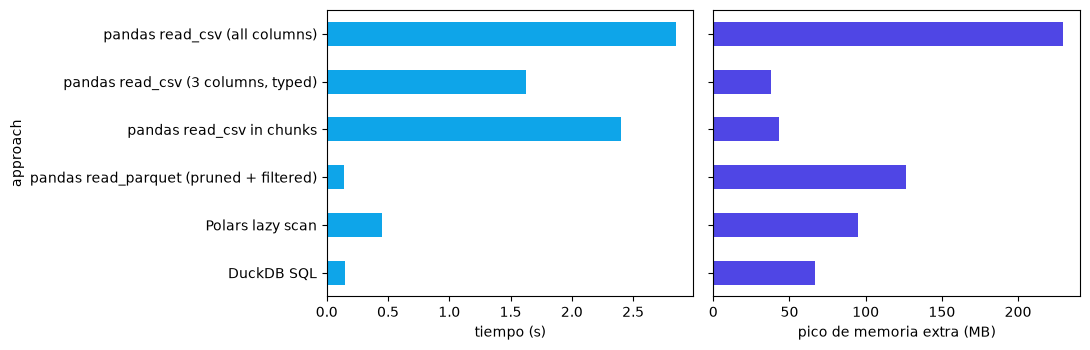

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
bench["seconds"].plot.barh(ax=ax[0], color="#0ea5e9"); ax[0].set_xlabel("tiempo (s)")
bench["peak_mb"].plot.barh(ax=ax[1], color="#4f46e5"); ax[1].set_xlabel("pico de memoria extra (MB)")
ax[0].invert_yaxis(); plt.tight_layout(); plt.show()

**Qué dicen los números.** Dos objetivos distintos, dos ganadores distintos:
- **La velocidad** viene del formato del archivo y del motor. Leer un Parquet columnar con poda de columnas y
  un filtro, o dejar que DuckDB o Polars ejecuten la consulta, es entre 6 y 20 veces más rápido que analizar el
  CSV, porque nunca se lee ni se convierte desde texto nada irrelevante.
- **La memoria** se ahorra guardando menos. Cargar el CSV entero con los tipos por defecto es, con diferencia,
  la opción que más memoria consume. Pedir a pandas solo tres columnas con tipos compactos, o procesar por
  bloques, reduce el pico entre cinco y seis veces, pero analizar texto sigue siendo lento.
- La memoria extra que aparece para Parquet, Polars y DuckDB es sobre todo la carga de las propias
  bibliotecas (los motores de Arrow y DuckDB ocupan decenas de MB cada uno); con este tamaño de datos ese coste
  fijo domina. Se mantiene casi constante al crecer los datos, mientras que una carga completa con pandas
  crece con el archivo.

En la práctica: guarda los datos en Parquet, selecciona columnas y tipos de entrada, y deja que un motor de
consultas (DuckDB o Polars) filtre y agregue; procesa por flujo cuando ni siquiera los datos seleccionados quepan.

## 7. Más allá de una máquina: PySpark
Cuando los datos ya no caben en una máquina (cientos de GB, muchos TB), o llegan continuamente desde muchas
fuentes, la herramienta estándar es **Apache Spark**, que se usa desde Python con **PySpark**. Spark divide un
conjunto de datos en **particiones** y las procesa en paralelo en muchos **ejecutores** (procesos de trabajo,
a menudo en muchos servidores), coordinados por un **driver** (tu programa de Python). Como el modo diferido de
Polars, nada se ejecuta hasta que pides un resultado: Spark primero construye un plan, y su optimizador
(*Catalyst*) lo reescribe empujando los filtros y la selección de columnas hasta la lectura del archivo.

| Concepto | Significado |
|---|---|
| `SparkSession` | el punto de entrada; se conecta a un clúster o lo ejecuta todo dentro de una máquina con `local[*]` |
| DataFrame | una tabla distribuida con esquema, dividida en particiones |
| transformación | `filter`, `select`, `groupBy`, `join`: diferida, solo añade pasos al plan |
| acción | `show`, `count`, `collect`, `write`: ejecuta el plan |
| gestor de clúster | de dónde salen los ejecutores: Kubernetes, YARN, Databricks, AWS EMR, Google Dataproc |

El mismo código se ejecuta en un portátil en modo local y en un clúster de 100 nodos; solo cambia la
configuración de la sesión. Spark se ejecuta en la máquina virtual de Java, así que necesita un entorno de
ejecución de Java (versión 17 o posterior).

In [11]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (SparkSession.builder
         .master("local[4]")                                   # 4 worker threads on this machine
         .appName("python1001-large-data")
         .config("spark.driver.memory", "2g")
         .config("spark.sql.shuffle.partitions", "8")         # small data: few partitions after a shuffle
         .config("spark.ui.enabled", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

readings = spark.read.parquet(PARQUET)                          # lazy: only the schema is read
readings.printSchema()
print("partitions:", readings.rdd.getNumPartitions(), "| rows:", f"{readings.count():,}")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/18 12:08:40 WARN Utils: Your hostname, patito-HP-Laptop-15-db0xxx, resolves to a loopback address: 127.0.1.1; using 192.168.0.16 instead (on interface wlo1)
26/10/18 12:08:40 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/18 12:08:51 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0


root
 |-- sensor_id: short (nullable = true)
 |-- temperature: float (nullable = true)
 |-- status: string (nullable = true)
 |-- site: string (nullable = true)
 |-- note: string (nullable = true)



partitions: 4 | rows: 3,000,000


### Dos maneras de escribir la misma consulta
Spark ofrece dos interfaces equivalentes, y los equipos las combinan libremente:

1. **La API de DataFrame**: llamadas a métodos sobre el DataFrame, con expresiones de columna de
   `pyspark.sql.functions` (`F.col`, `F.avg`, `F.when`, ...). Componible, comprobada por tu editor y fácil de
   construir desde código.
2. **SQL**: registra el DataFrame como una vista y ejecuta una consulta en texto con `spark.sql("...")`.
   Familiar para cualquiera que sepa SQL y cómodo para consultas analíticas largas.

**Consulta 1:** temperatura media y número de lecturas `fault` por sitio.

In [12]:
# 1) DataFrame API
api_result = (readings
              .filter(F.col("status") == "fault")
              .groupBy("site")
              .agg(F.round(F.avg("temperature"), 3).alias("mean_temp"), F.count("*").alias("n_faults"))
              .orderBy("site"))
api_result.show(5)

+-------+---------+--------+
|   site|mean_temp|n_faults|
+-------+---------+--------+
| site_0|   21.058|    1510|
| site_1|   21.014|    1453|
|site_10|   20.882|    1456|
|site_11|   20.892|    1484|
|site_12|   21.072|    1512|
+-------+---------+--------+
only showing top 5 rows


In [13]:
# 2) SQL: the DataFrame becomes a temporary view that queries can refer to by name
readings.createOrReplaceTempView("readings")
sql_result = spark.sql('''
    SELECT site,
           ROUND(AVG(temperature), 3) AS mean_temp,
           COUNT(*)                   AS n_faults
    FROM readings
    WHERE status = 'fault'
    GROUP BY site
    ORDER BY site
''')
sql_result.show(5)
print("resultados idénticos:", api_result.collect() == sql_result.collect())

+-------+---------+--------+
|   site|mean_temp|n_faults|
+-------+---------+--------+
| site_0|   21.058|    1510|
| site_1|   21.014|    1453|
|site_10|   20.882|    1456|
|site_11|   20.892|    1484|
|site_12|   21.072|    1512|
+-------+---------+--------+
only showing top 5 rows


resultados idénticos: True


Las dos las compila el mismo optimizador en el mismo tipo de plan físico, así que ninguna es más rápida. El
plan muestra la optimización en acción: el filtro sobre `status` y las tres columnas necesarias se empujan
hasta la lectura del Parquet (`PushedFilters`, `ReadSchema`), de modo que las demás columnas nunca se leen.

In [14]:
api_result.explain()          # the DataFrame API version
sql_result.explain()          # the SQL version: the same operators

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=true
+- == Final Plan ==
   ResultQueryStage 2
   +- *(3) Sort [site#3 ASC NULLS FIRST], true, 0
      +- AQEShuffleRead coalesced
         +- ShuffleQueryStage 1
            +- Exchange rangepartitioning(site#3 ASC NULLS FIRST, 8), ENSURE_REQUIREMENTS, [plan_id=260]
               +- *(2) HashAggregate(keys=[site#3], functions=[avg(temperature#1), count(1)])
                  +- AQEShuffleRead coalesced
                     +- ShuffleQueryStage 0
                        +- Exchange hashpartitioning(site#3, 8), ENSURE_REQUIREMENTS, [plan_id=228]
                           +- *(1) HashAggregate(keys=[site#3], functions=[partial_avg(temperature#1), partial_count(1)])
                              +- *(1) Project [temperature#1, site#3]
                                 +- *(1) Filter (isnotnull(status#2) AND (status#2 = fault))
                                    +- *(1) ColumnarToRow
                                       +- FileScan parq

**Consulta 2:** algo más completo. Por sitio, el porcentaje de lecturas en cada estado y los tres sensores con
la temperatura media más alta, usando una columna derivada, una tabla dinámica (pivot), una unión (join) y
una **función de ventana**.

In [15]:
# DataFrame API
flagged = readings.withColumn("is_hot", F.when(F.col("temperature") > 28, 1).otherwise(0))
status_share = (flagged.groupBy("site").pivot("status", ["ok", "warning", "fault"]).count()
                .withColumn("total", F.col("ok") + F.col("warning") + F.col("fault"))
                .select("site", *[F.round(F.col(s) / F.col("total") * 100, 2).alias(f"pct_{s}") for s in ["ok", "warning", "fault"]]))
by_sensor = flagged.groupBy("site", "sensor_id").agg(F.avg("temperature").alias("avg_t"), F.sum("is_hot").alias("hot_readings"))
rank_w = Window.partitionBy("site").orderBy(F.col("avg_t").desc())
top3_api = (by_sensor.withColumn("rank", F.row_number().over(rank_w)).filter(F.col("rank") <= 3)
            .join(F.broadcast(status_share), "site")                     # small table: send it to every executor
            .orderBy("site", "rank"))
top3_api.show(6)

+------+---------+------------------+------------+----+------+-----------+---------+
|  site|sensor_id|             avg_t|hot_readings|rank|pct_ok|pct_warning|pct_fault|
+------+---------+------------------+------------+----+------+-----------+---------+
|site_0|      195|22.334422131518384|          14|   1| 89.92|       8.06|     2.02|
|site_0|      191|22.060088488459588|          11|   2| 89.92|       8.06|     2.02|
|site_0|      217|21.775642860226515|           8|   3| 89.92|       8.06|     2.02|
|site_1|      313|   22.034557895806|          12|   1| 90.11|       7.96|     1.94|
|site_1|      228|21.965595207214356|           8|   2| 90.11|       7.96|     1.94|
|site_1|      107|21.913695235925218|          12|   3| 90.11|       7.96|     1.94|
+------+---------+------------------+------------+----+------+-----------+---------+
only showing top 6 rows


In [16]:
# SQL: the same logic, with CTEs, CASE WHEN, conditional aggregation and ROW_NUMBER() OVER (...)
top3_sql = spark.sql('''
    WITH flagged AS (
        SELECT *, CASE WHEN temperature > 28 THEN 1 ELSE 0 END AS is_hot FROM readings
    ),
    status_share AS (
        SELECT site,
               ROUND(100 * AVG(CASE WHEN status = 'ok'      THEN 1 ELSE 0 END), 2) AS pct_ok,
               ROUND(100 * AVG(CASE WHEN status = 'warning' THEN 1 ELSE 0 END), 2) AS pct_warning,
               ROUND(100 * AVG(CASE WHEN status = 'fault'   THEN 1 ELSE 0 END), 2) AS pct_fault
        FROM flagged GROUP BY site
    ),
    ranked AS (
        SELECT site, sensor_id, AVG(temperature) AS avg_t, SUM(is_hot) AS hot_readings,
               ROW_NUMBER() OVER (PARTITION BY site ORDER BY AVG(temperature) DESC) AS rank
        FROM flagged GROUP BY site, sensor_id
    )
    SELECT r.*, s.pct_ok, s.pct_warning, s.pct_fault
    FROM ranked r JOIN status_share s USING (site)
    WHERE rank <= 3
    ORDER BY site, rank
''')
top3_sql.show(6)
cols = ["site", "sensor_id", "rank", "pct_fault"]
print("mismas filas:", top3_api.select(cols).collect() == top3_sql.select(cols).collect())

+------+---------+------------------+------------+----+------+-----------+---------+
|  site|sensor_id|             avg_t|hot_readings|rank|pct_ok|pct_warning|pct_fault|
+------+---------+------------------+------------+----+------+-----------+---------+
|site_0|      195|22.334422131518384|          14|   1| 89.92|       8.06|     2.02|
|site_0|      191|22.060088488459588|          11|   2| 89.92|       8.06|     2.02|
|site_0|      217|21.775642860226515|           8|   3| 89.92|       8.06|     2.02|
|site_1|      313|   22.034557895806|          12|   1| 90.11|       7.96|     1.94|
|site_1|      228|21.965595207214356|           8|   2| 90.11|       7.96|     1.94|
|site_1|      107|21.913695235925218|          12|   3| 90.11|       7.96|     1.94|
+------+---------+------------------+------------+----+------+-----------+---------+
only showing top 6 rows


mismas filas: True


### Sacar resultados y escribir datos
`toPandas()` trae un resultado al driver como un DataFrame de pandas: hazlo solo con resultados **pequeños**,
nunca con los datos en bruto. Las salidas grandes se escriben de vuelta al almacenamiento, normalmente en
Parquet particionado por una columna, para que las consultas posteriores puedan saltarse carpetas enteras.

In [17]:
small = top3_sql.toPandas()                       # fine: a few hundred rows
print(type(small).__name__, small.shape)

out = os.path.join(tmp, "spark_out")
(readings.filter(F.col("status") != "ok")
         .write.mode("overwrite").partitionBy("status").parquet(out))
print(sorted(d for d in os.listdir(out) if not d.startswith(("_", "."))))
# SQL can also query files directly, without registering a view first
spark.sql(f"SELECT status, COUNT(*) AS n FROM parquet.`{out}` GROUP BY status ORDER BY status").show()

DataFrame (120, 8)


['status=fault', 'status=warning']


+-------+------+
| status|     n|
+-------+------+
|  fault| 59835|
|warning|240089|
+-------+------+



### ¿Es Spark más rápido aquí?

In [18]:
import time
t0 = time.perf_counter(); api_result.collect(); t_spark = time.perf_counter() - t0
t0 = time.perf_counter()
duckdb.sql(f"select site, avg(temperature), count(*) from '{PARQUET}' where status = 'fault' group by site").df()
t_duck = time.perf_counter() - t0
print(f"consulta 1 con ambos motores ya en marcha: Spark {t_spark:.2f} s, DuckDB {t_duck:.2f} s")
spark.stop()

consulta 1 con ambos motores ya en marcha: Spark 0.10 s, DuckDB 0.05 s


En una sola máquina y con unos pocos millones de filas, no: Spark planifica la consulta, reparte tareas y mueve
datos entre ellas en un proceso de Java aparte, costes que evitan los motores de un solo nodo como DuckDB y
Polars. Spark compensa cuando los datos o el trabajo son demasiado grandes para una máquina, cuando los datos ya
viven en un data lake o un almacén de datos que Spark lee de forma nativa, o en flujos de datos en tiempo real.
Un camino sensato: pandas, después Polars o DuckDB, después Spark.

| Herramienta | API de funciones | Estilo SQL |
|---|---|---|
| **PySpark** | `df.filter(F.col("x") > 1).groupBy("k").agg(F.avg("v"))` | `df.createOrReplaceTempView("t")` y después `spark.sql("SELECT k, AVG(v) FROM t WHERE x > 1 GROUP BY k")` |
| **Polars** | `df.filter(pl.col("x") > 1).group_by("k").agg(pl.col("v").mean())` | `df.sql("SELECT k, AVG(v) FROM self WHERE x > 1 GROUP BY k")` |
| **DuckDB** | API relacional: `duckdb.table("t").filter("x > 1").aggregate("k, avg(v)")` | `duckdb.sql("SELECT ...")`, que también puede consultar DataFrames de pandas por su nombre |
| **pandas** | `df[df.x > 1].groupby("k")["v"].mean()` | `df.query("x > 1")` recibe una expresión de filtro, no SQL completo |

Spark también ofrece una API parecida a pandas (`import pyspark.pandas as ps`) para equipos que llevan código
pandas a un clúster.

## Lista de comprobación para procesar con memoria limitada
1. **Mide primero**: `memory_usage(deep=True)`, `psutil` o el pico de una ejecución de prueba.
2. **Guarda en Parquet**, no en CSV, y lee solo las columnas y filas necesarias.
3. **Usa los tipos adecuados**: `category` para cadenas repetidas, `float32`/enteros pequeños donde la precisión lo permita.
4. **Procesa por flujo** cuando el resultado sea pequeño: bloques, generadores o un motor diferido.
5. **Borra lo que ya no necesites** (`del df`) y evita copias accidentales.
6. **Deja el trabajo a un motor de consultas** (DuckDB, Polars) cuando pandas lo cargaría todo.
7. Solo entonces piensa en más RAM o en un clúster (Spark, sección 7).

## Ejercicios
1. Repite la comparativa agrupando por `sensor_id`. ¿Cambia la clasificación?
2. Añade un enfoque con `pyarrow.dataset` y una expresión de filtro, y compáralo.
3. Usa `pl.scan_csv` en lugar de `scan_parquet`: ¿cuánta ventaja de Polars viene del formato del archivo?
4. En PySpark, encuentra la lectura más caliente de cada sitio dos veces: con `Window` y `F.max`, y en SQL con `MAX(...) OVER (PARTITION BY site)`. Comprueba que ambas dan las mismas filas.